<a href="https://colab.research.google.com/github/UnnimayaVAshok/my_projects/blob/main/penguin_species.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_csv("Penguin Species Prediction Dataset.csv")
df = pd.DataFrame(data)
df

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,41.1,18.4,195.0,3886.0,Female
1,Gentoo,Biscoe,50.0,15.4,217.0,4303.0,Male
2,Gentoo,Biscoe,50.0,15.1,220.0,4954.0,Female
3,Chinstrap,Dream,48.7,19.0,196.0,3739.0,Male
4,Adelie,Dream,39.0,17.8,187.0,3607.0,Male
...,...,...,...,...,...,...,...
995,Adelie,Dream,41.5,20.5,182.0,3931.0,Male
996,Gentoo,Biscoe,46.6,14.7,224.0,5050.0,Female
997,Adelie,Dream,36.4,16.6,183.0,3572.0,Male
998,Gentoo,Biscoe,47.9,15.0,213.0,5414.0,Female


In [ ]:
df.columns

Index(['species', 'island', 'culmen_length_mm', 'culmen_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='object')

In [ ]:
df.shape

(1000, 7)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            1000 non-null   object 
 1   island             1000 non-null   object 
 2   culmen_length_mm   990 non-null    float64
 3   culmen_depth_mm    990 non-null    float64
 4   flipper_length_mm  990 non-null    float64
 5   body_mass_g        990 non-null    float64
 6   sex                990 non-null    object 
dtypes: float64(4), object(3)
memory usage: 54.8+ KB


In [ ]:
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,990.000000,990.000000,990.000000,990.000000
mean,43.817778,17.335556,199.224242,4103.311111
std,5.309985,1.779057,13.171660,705.334794
min,32.400000,13.000000,175.000000,2830.000000
25%,39.000000,15.800000,189.000000,3586.000000
50%,43.800000,17.800000,195.000000,3882.000000
75%,48.300000,18.700000,212.000000,4587.000000
max,56.000000,21.400000,235.000000,6317.000000


In [ ]:
df.isna().sum()

,0
species,0
island,0
culmen_length_mm,10
culmen_depth_mm,10
flipper_length_mm,10
body_mass_g,10
sex,10


In [ ]:
columns = ["culmen_length_mm", "culmen_depth_mm","flipper_length_mm", "body_mass_g"]
for i in columns:
  df[i] = df[i].fillna(df[i].mean())
df["sex"] = df["sex"].fillna(df["sex"].mode()[0])

In [ ]:
df.isna().sum()

,0
species,0
island,0
culmen_length_mm,0
culmen_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["species"].value_counts()

,count
species,
Adelie,461
Gentoo,288
Chinstrap,251


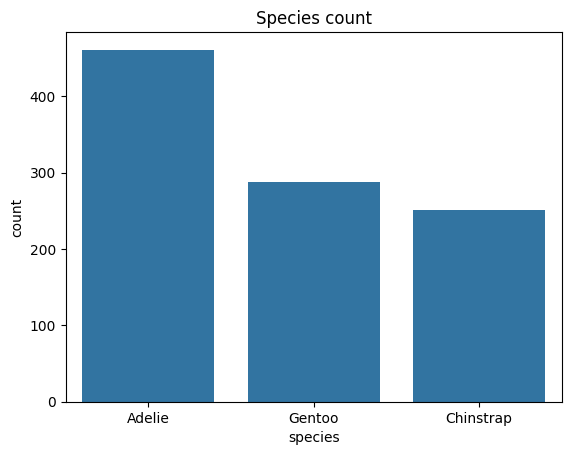

In [ ]:
sns.countplot(data = df,x = "species")
plt.title("Species count")
plt.show()

In [ ]:
df["island"].nunique()

3

In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["island"] = le.fit_transform(df["island"])
df["sex"] = le.fit_transform(df["sex"])

In [ ]:
X = df.drop("species",axis = 1)
y = df["species"]
X,y

(     island  culmen_length_mm  culmen_depth_mm  flipper_length_mm  \
 0         2              41.1             18.4              195.0   
 1         0              50.0             15.4              217.0   
 2         0              50.0             15.1              220.0   
 3         1              48.7             19.0              196.0   
 4         1              39.0             17.8              187.0   
 ..      ...               ...              ...                ...   
 995       1              41.5             20.5              182.0   
 996       0              46.6             14.7              224.0   
 997       1              36.4             16.6              183.0   
 998       0              47.9             15.0              213.0   
 999       1              38.5             18.9              187.0   
 
      body_mass_g  sex  
 0         3886.0    0  
 1         4303.0    1  
 2         4954.0    0  
 3         3739.0    1  
 4         3607.0    1  
 ..     

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.3,random_state = 42,stratify = y)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
y_pred

array(['Chinstrap', 'Adelie', 'Adelie', 'Adelie', 'Gentoo', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Gentoo', 'Gentoo', 'Adelie',
       'Chinstrap', 'Chinstrap', 'Adelie', 'Adelie', 'Gentoo', 'Adelie',
       'Adelie', 'Gentoo', 'Adelie', 'Adelie', 'Gentoo', 'Gentoo',
       'Chinstrap', 'Adelie', 'Chinstrap', 'Gentoo', 'Chinstrap',
       'Adelie', 'Gentoo', 'Gentoo', 'Adelie', 'Chinstrap', 'Adelie',
       'Gentoo', 'Gentoo', 'Adelie', 'Adelie', 'Adelie', 'Gentoo',
       'Gentoo', 'Adelie', 'Gentoo', 'Chinstrap', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Gentoo', 'Chinstrap', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Gentoo', 'Adelie', 'Adelie', 'Gentoo',
       'Chinstrap', 'Adelie', 'Adelie', 'Chinstrap', 'Chinstrap',
       'Adelie', 'Chinstrap', 'Adelie', 'Adelie', 'Chinstrap', 'Gentoo',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Chinstrap', 'Adelie',
       'Chinstrap', 'Chinstrap', 'Adelie', 'Adelie', 'Adelie', 'Gentoo',
       'Adelie', 'Chinstrap', '

In [ ]:
from sklearn.metrics import accuracy_score,recall_score,confusion_matrix,classification_report

print(accuracy_score(y_test,y_pred))
#print(recall_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

0.9966666666666667
[[138   0   0]
 [  1  74   0]
 [  0   0  87]]
              precision    recall  f1-score   support

      Adelie       0.99      1.00      1.00       138
   Chinstrap       1.00      0.99      0.99        75
      Gentoo       1.00      1.00      1.00        87

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300

